In [27]:
import pandas as pd
import numpy as np

In [28]:
df=pd.read_csv("cleaned_all_stocks_5yr.csv")

In [29]:
import pandas as pd
import numpy as np
import yfinance as yf

# 1. ترتيب البيانات زمنياً لكل سهم بدقة
df['date'] = pd.to_datetime(df['date'], errors='coerce')
df = df.sort_values(by=['Name', 'date']).reset_index(drop=True)

start_date = df['date'].min().strftime('%Y-%m-%d')
end_date = df['date'].max().strftime('%Y-%m-%d')

# سحب بيانات مؤشر السوق العام
market_data = yf.download('^GSPC', start=start_date, end=end_date)
if isinstance(market_data.columns, pd.MultiIndex):
    market_data.columns = market_data.columns.get_level_values(0)
market_data = market_data.reset_index()
market_df = market_data[['Date', 'Close']].rename(columns={'Close': 'Market_Close', 'Date': 'date'})
market_df['date'] = pd.to_datetime(market_df['date'])

df = pd.merge(df, market_df, on='date', how='left')
df['Market_Close'] = df['Market_Close'].ffill()

# 2. المؤشرات الأساسية والفنية الاحترافية
df['Price_Range'] = df['high'] - df['low']
df['Daily_Change'] = df['close'] - df['open']

df['avg_close_10d'] = df.groupby('Name')['close'].transform(lambda s: s.shift(1).rolling(10).mean())
df['trend_10d'] = df['close'] - df['avg_close_10d']

# مؤشر الزخم RSI
def compute_rsi(series, period=14):
    delta = series.diff()
    gain = (delta.where(delta > 0, 0)).rolling(window=period).mean()
    loss = (-delta.where(delta < 0, 0)).rolling(window=period).mean()
    rs = gain / (loss + 1e-8)
    return 100 - (100 / (1 + rs))

df['RSI'] = df.groupby('Name')['close'].transform(lambda x: compute_rsi(x))

# مؤشر MACD
exp12 = df.groupby('Name')['close'].transform(lambda x: x.ewm(span=12, adjust=False).mean())
exp26 = df.groupby('Name')['close'].transform(lambda x: x.ewm(span=26, adjust=False).mean())
df['MACD'] = exp12 - exp26

# مؤشر Bollinger Bands Width
rolling_mean = df.groupby('Name')['close'].transform(lambda x: x.rolling(20).mean())
rolling_std = df.groupby('Name')['close'].transform(lambda x: x.rolling(20).std())
df['BB_Width'] = (4 * rolling_std) / (rolling_mean + 1e-8)

# مؤشر السوق وصدمة الحجم
df['Market_Return'] = df.groupby('Name')['Market_Close'].pct_change()
df['Volume_SMA_10'] = df.groupby('Name')['volume'].transform(lambda x: x.rolling(window=10).mean())
df['Volume_Ratio'] = df['volume'] / df['Volume_SMA_10']
df['Return_5d'] = df.groupby('Name')['close'].pct_change(periods=5)
df['Price_to_High_20d'] = df['close'] / df.groupby('Name')['high'].transform(lambda x: x.rolling(20).max())
df.dropna(inplace=True)
df.reset_index(drop=True, inplace=True)
# 3. **إضافة جديدة:** عوائد الأيام السابقة (Lag Returns) ليعرف المودل الزخم
df['Return_1d'] = df.groupby('Name')['close'].pct_change()
df['Return_2d'] = df.groupby('Name')['close'].pct_change(periods=2)

# 4. **التعديل الجذري للـ Target:** العائد على مدار 3 أيام قادمة ممهد لتقليل التشويش
df['Target_Return'] = (df.groupby('Name')['close'].shift(-3) / df['close'] - 1).rolling(window=2, min_periods=1).mean()

# تنظيف القيم الفارغة
df.dropna(inplace=True)
df.reset_index(drop=True, inplace=True)

print("تم تطبيق التعديلات والتحسينات بنجاح! الشكل النهائي للداتا:", df.shape)

/tmp/ipykernel_4036/1319981285.py:13: FutureWarning: YF.download() has changed argument auto_adjust default to True
  market_data = yf.download('^GSPC', start=start_date, end=end_date)
[*********************100%***********************]  1 of 1 completed


تم تطبيق التعديلات والتحسينات بنجاح! الشكل النهائي للداتا: (607414, 23)


In [30]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 607414 entries, 0 to 607413
Data columns (total 23 columns):
 #   Column             Non-Null Count   Dtype         
---  ------             --------------   -----         
 0   date               607414 non-null  datetime64[ns]
 1   open               607414 non-null  float64       
 2   high               607414 non-null  float64       
 3   low                607414 non-null  float64       
 4   close              607414 non-null  float64       
 5   volume             607414 non-null  int64         
 6   Name               607414 non-null  object        
 7   Market_Close       607414 non-null  float64       
 8   Price_Range        607414 non-null  float64       
 9   Daily_Change       607414 non-null  float64       
 10  avg_close_10d      607414 non-null  float64       
 11  trend_10d          607414 non-null  float64       
 12  RSI                607414 non-null  float64       
 13  MACD               607414 non-null  float64 

In [31]:
print(df[df['Name'] == 'A'][['date', 'close', 'Target_Return']].head(5))

        date  close  Target_Return
0 2013-03-12  42.62       0.010532
1 2013-03-13  43.00      -0.000657
2 2013-03-14  43.32      -0.020468
3 2013-03-15  43.01      -0.018839
4 2013-03-18  42.55      -0.014180


In [32]:
import matplotlib.pyplot as plt
import seaborn as sns

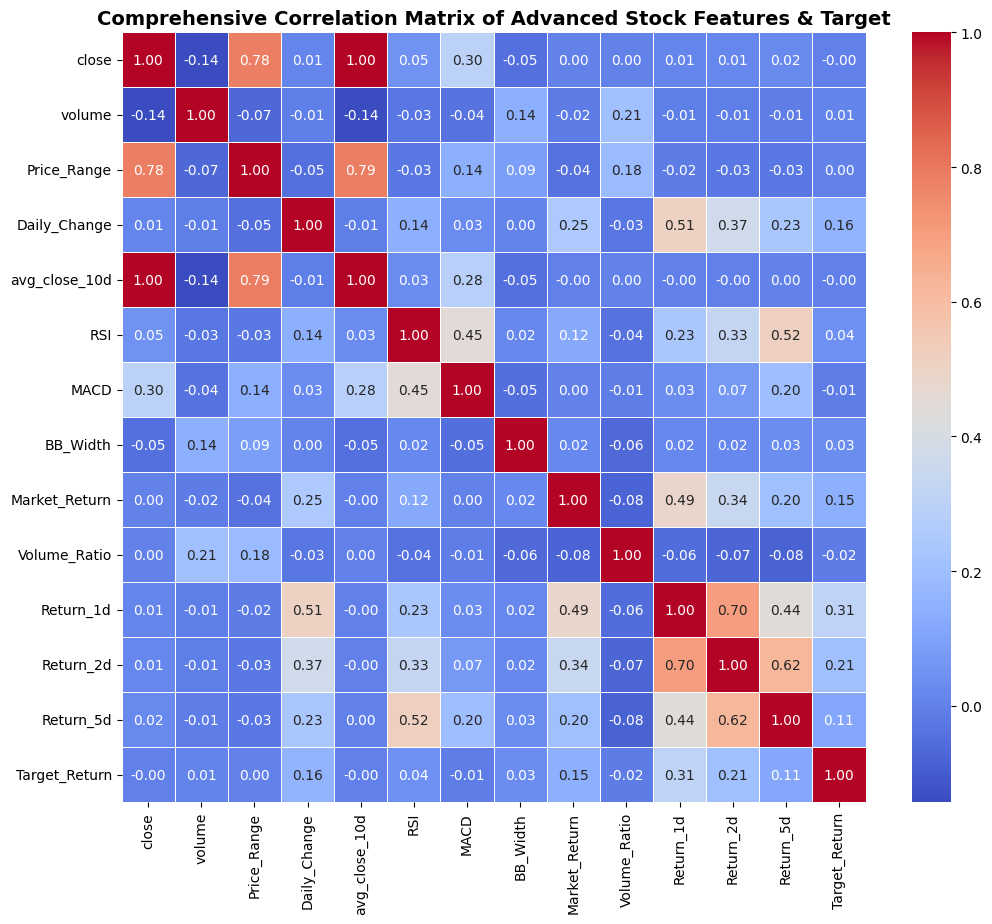

In [33]:
plt.figure(figsize=(12, 10))

# اختيار أهم الأعمدة والميزات المتقدمة الجديدة مع الهدف
corr_cols = [
    'close', 'volume', 'Price_Range', 'Daily_Change', 'avg_close_10d',
    'RSI', 'MACD', 'BB_Width', 'Market_Return', 'Volume_Ratio',
    'Return_1d', 'Return_2d', 'Return_5d', 'ATR', 'Price_Slope', 'Target_Return'
]

# التأكد من أن الأعمدة موجودة فعلياً في الـ DataFrame لتجنب أي خطأ
existing_cols = [col for col in corr_cols if col in df.columns]

# رسم الـ Heatmap بوضوح واحترافية
sns.heatmap(df[existing_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', linewidths=0.5, cbar=True)

plt.title('Comprehensive Correlation Matrix of Advanced Stock Features & Target', fontsize=14, fontweight='bold')
plt.show()

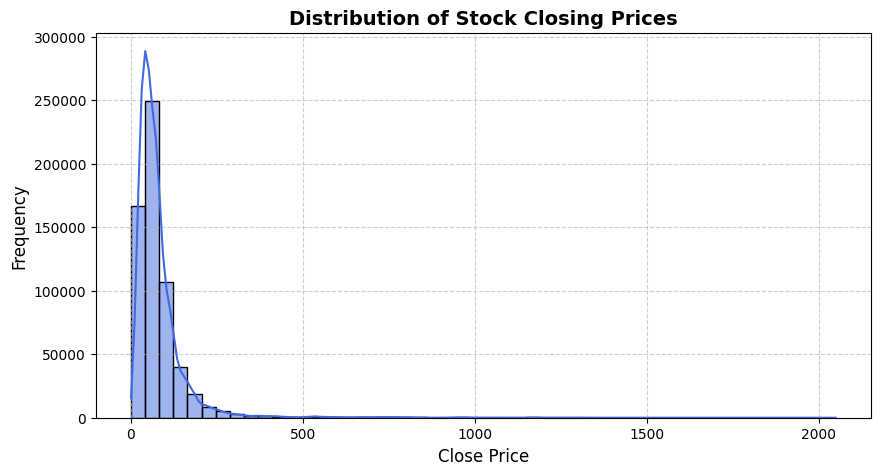

In [34]:
# 1. رسم توزع أسعار الإغلاق (Histogram & KDE)
plt.figure(figsize=(10, 5))
sns.histplot(df['close'], bins=50, kde=True, color='royalblue')
plt.title('Distribution of Stock Closing Prices', fontsize=14, fontweight='bold')
plt.xlabel('Close Price', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

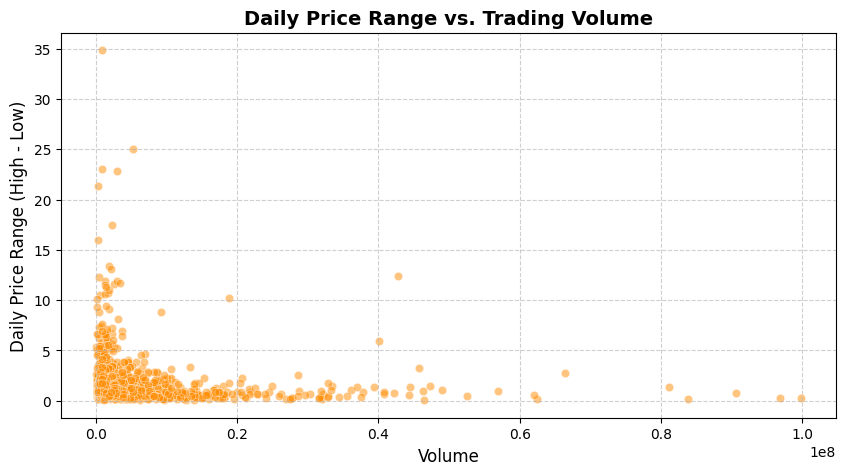

In [35]:
plt.figure(figsize=(10, 5))
sample_df = df.sample(n=2000, random_state=42) # أخذ عينة لتسهيل العرض البصري
sns.scatterplot(x='volume', y='Price_Range', data=sample_df, alpha=0.5, color='darkorange')
plt.title('Daily Price Range vs. Trading Volume', fontsize=14, fontweight='bold')
plt.xlabel('Volume', fontsize=12)
plt.ylabel('Daily Price Range (High - Low)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

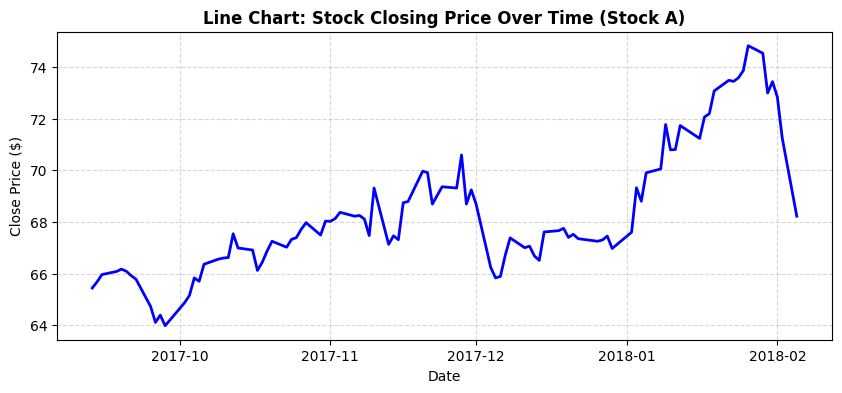

In [36]:
stock_a = df[df['Name'] == 'A'].tail(100) # آخر 100 يوم لتسهيل العرض

plt.figure(figsize=(10, 4))
plt.plot(stock_a['date'], stock_a['close'], color='blue', linewidth=2)
plt.title('Line Chart: Stock Closing Price Over Time (Stock A)', fontsize=12, fontweight='bold')
plt.xlabel('Date', fontsize=10)
plt.ylabel('Close Price ($)', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

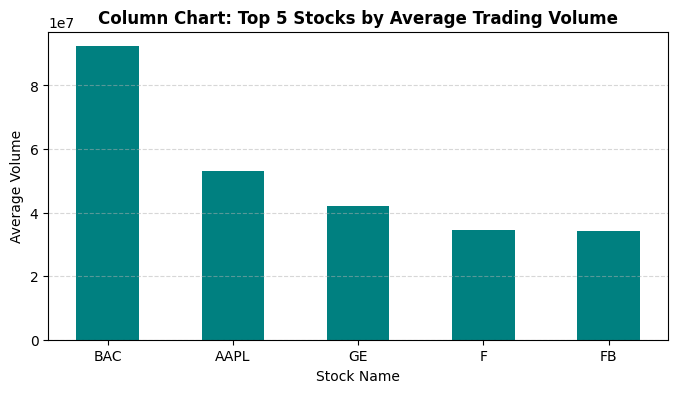

In [37]:
top_stocks = df.groupby('Name')['volume'].mean().nlargest(5).reset_index()

plt.figure(figsize=(8, 4))
plt.bar(top_stocks['Name'], top_stocks['volume'], color='teal', width=0.5)
plt.title('Column Chart: Top 5 Stocks by Average Trading Volume', fontsize=12, fontweight='bold')
plt.xlabel('Stock Name', fontsize=10)
plt.ylabel('Average Volume', fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

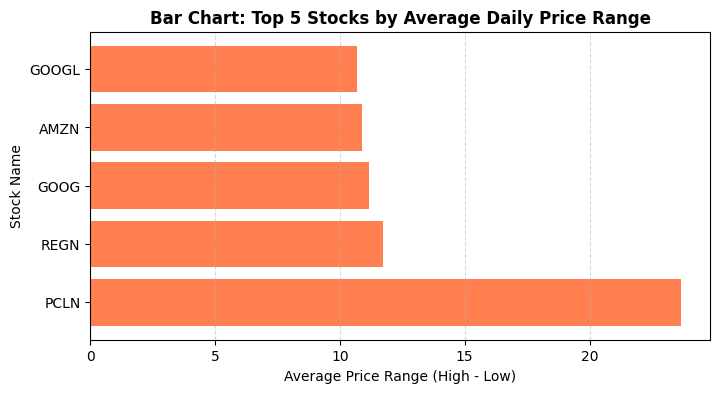

In [38]:
top_range = df.groupby('Name')['Price_Range'].mean().nlargest(5).reset_index()

plt.figure(figsize=(8, 4))
plt.barh(top_range['Name'], top_range['Price_Range'], color='coral')
plt.title('Bar Chart: Top 5 Stocks by Average Daily Price Range', fontsize=12, fontweight='bold')
plt.xlabel('Average Price Range (High - Low)', fontsize=10)
plt.ylabel('Stock Name', fontsize=10)
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.show()